<a href="https://colab.research.google.com/github/irfan060606/Scikit-Learn-Cookbook/blob/main/Chapter_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 8 — Tree-Based Algorithms and Ensemble Methods

This notebook studies tree-based supervised learning models using **scikit-learn**. It follows the main topics of Chapter 8 of *scikit-learn Cookbook, Third Edition*:

1. Introduction to decision trees
2. Random forests and bagging
3. Gradient boosting machines
4. Hyperparameter tuning for trees and ensembles
5. Comparing ensemble methods

The examples use the Iris dataset so the models can be trained and evaluated consistently. Additional exercises at the end revisit decision trees, random forests, and gradient boosting.

## Learning objectives

After completing this notebook, you should be able to:

- Explain how decision trees divide data into smaller groups.
- Distinguish a single decision tree from a bagging-based random forest and a boosting model.
- Train and evaluate tree-based classifiers.
- Interpret feature importance with appropriate caution.
- Use cross-validation and `GridSearchCV` to tune model hyperparameters.
- Compare different ensemble approaches on the same test set.

**Reproducibility:** the dataset split and randomized estimators use fixed random seeds. Exact scores can vary slightly across scikit-learn versions.

## 1. Environment setup and dataset

We will use the built-in **Iris** dataset. Each sample has four measurements of a flower and belongs to one of three species. No external data download is required.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    StackingClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
)

RANDOM_STATE = 2024

iris = load_iris()
X = iris.data
y = iris.target

feature_names = iris.feature_names
class_names = iris.target_names

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Dataset samples: {X.shape[0]}")
print(f"Features: {X.shape[1]}")
print(f"Classes: {list(class_names)}")
print(f"Training samples: {X_train.shape[0]}")
print(f"Test samples: {X_test.shape[0]}")

Dataset samples: 150
Features: 4
Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Training samples: 105
Test samples: 45


In [2]:
# Preview the structure of the data
iris_df = pd.DataFrame(X, columns=feature_names)
iris_df["species"] = [class_names[label] for label in y]
iris_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 2. Introduction to decision trees

A **decision tree** makes predictions by repeatedly splitting the data using feature-based rules. An internal node asks a question about a feature, a branch represents an answer, and a leaf node gives the prediction.

Decision trees are intuitive and can model non-linear relationships. However, a tree that grows too deep may memorize the training set instead of generalizing well to new data. This is called **overfitting**.

### Splitting criteria: Gini impurity and entropy

The model needs a way to choose a useful split:

- **Gini impurity** estimates how mixed the classes are in a node.
- **Entropy** measures class uncertainty and is used by the information-gain criterion.

A split is preferred when it creates child nodes that are more class-pure. In scikit-learn, `criterion="gini"` is a common default; `criterion="entropy"` is another option.

In [3]:
tree_model = DecisionTreeClassifier(
    criterion="gini",
    random_state=RANDOM_STATE,
)
tree_model.fit(X_train, y_train)

tree_predictions = tree_model.predict(X_test)
tree_accuracy = accuracy_score(y_test, tree_predictions)

print(f"Decision Tree test accuracy: {tree_accuracy:.3f}")
print("\nClassification report:")
print(
    classification_report(
        y_test,
        tree_predictions,
        target_names=class_names,
        zero_division=0,
    )
)

Decision Tree test accuracy: 0.911

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.87      0.87      0.87        15
   virginica       0.87      0.87      0.87        15

    accuracy                           0.91        45
   macro avg       0.91      0.91      0.91        45
weighted avg       0.91      0.91      0.91        45



### Visualizing the trained tree

A tree diagram helps reveal the decision rules learned from the training data. Each internal node shows a split condition and the distribution of class labels among samples reaching that node.

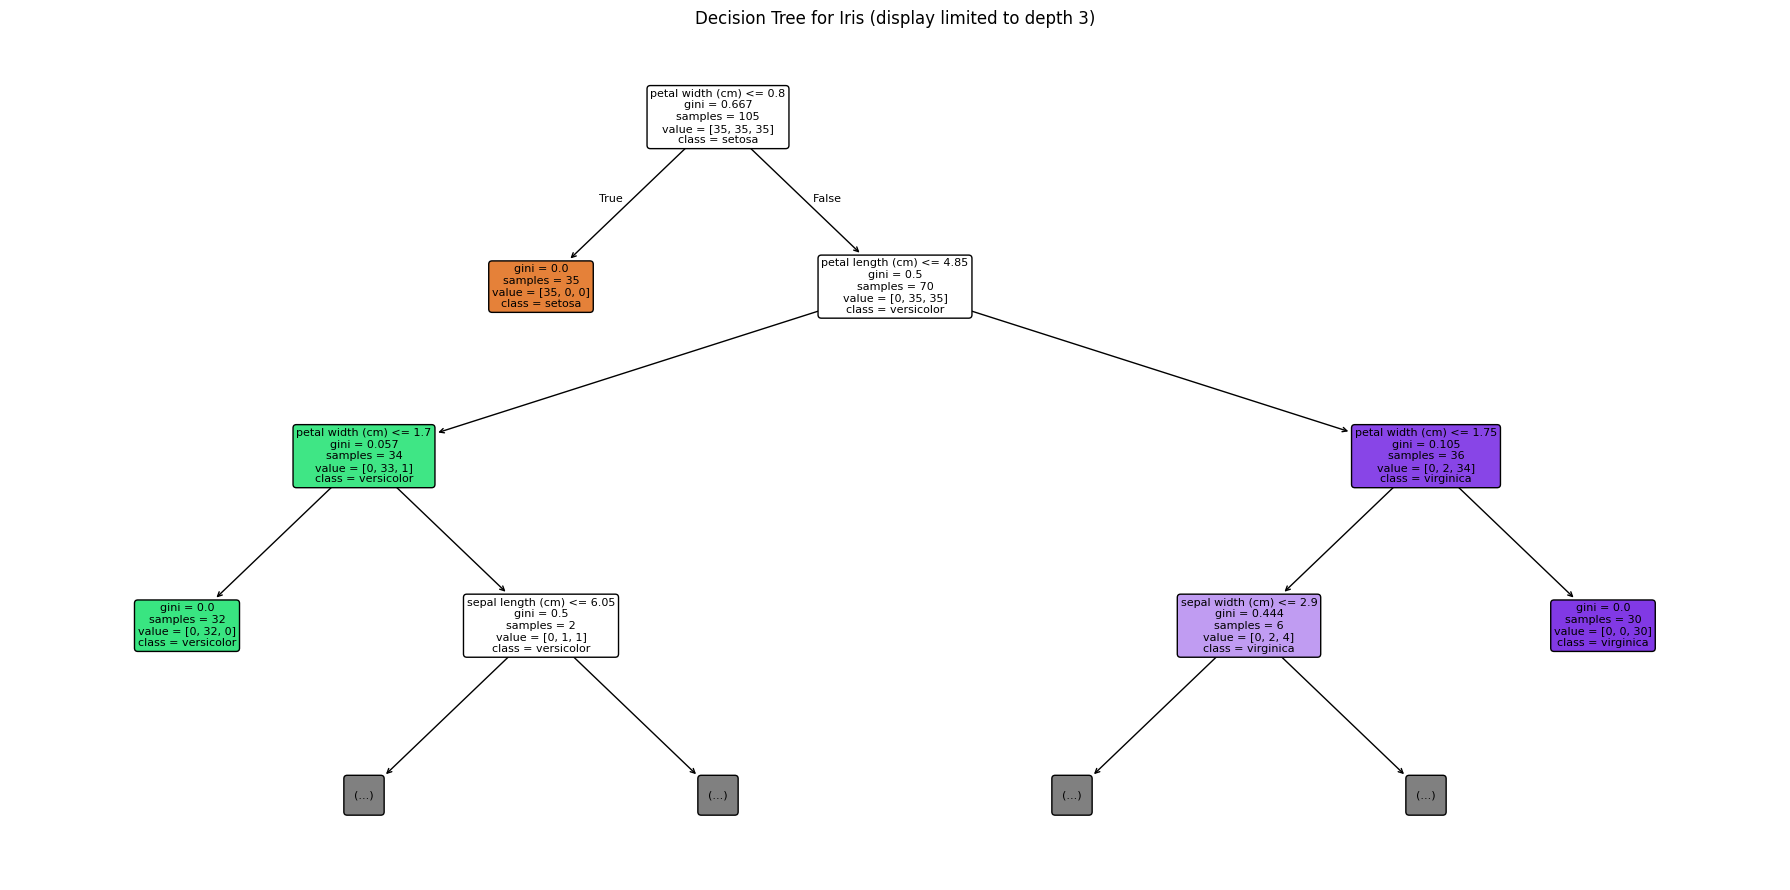

In [4]:
plt.figure(figsize=(18, 9))
plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=class_names,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8,
)
plt.title("Decision Tree for Iris (display limited to depth 3)")
plt.tight_layout()
plt.show()

### Controlling tree complexity

Several parameters can limit the size of a decision tree:

- `max_depth`: maximum depth of the tree.
- `min_samples_split`: minimum samples required to split an internal node.
- `min_samples_leaf`: minimum samples allowed in a leaf.
- `criterion`: function used to measure split quality.

A smaller tree is easier to interpret and may reduce overfitting, although restricting a tree too much can cause underfitting. Compare a default tree with a depth-limited tree using the training and test scores.

In [5]:
shallow_tree = DecisionTreeClassifier(
    max_depth=3,
    min_samples_leaf=2,
    random_state=RANDOM_STATE,
)
shallow_tree.fit(X_train, y_train)

complexity_results = pd.DataFrame({
    "Model": ["Default Decision Tree", "Depth-limited Decision Tree"],
    "Training accuracy": [
        tree_model.score(X_train, y_train),
        shallow_tree.score(X_train, y_train),
    ],
    "Test accuracy": [
        tree_model.score(X_test, y_test),
        shallow_tree.score(X_test, y_test),
    ],
})
complexity_results.round(3)

,Model,Training accuracy,Test accuracy
0,Default Decision Tree,1.000,0.911
1,Depth-limited Decision Tree,0.971,0.911


## 3. Random forests and bagging

A **random forest** combines many decision trees. It uses **bootstrap aggregating (bagging)**: individual trees are trained on samples drawn with replacement from the training data. Random forests also consider randomized subsets of features when splitting nodes.

For classification, the trees vote for a class and the forest returns the aggregated prediction. This averaging often reduces the variance of a single decision tree and can improve generalization.

Important parameters include:

- `n_estimators`: number of trees in the forest.
- `max_depth`: maximum depth for each tree.
- `max_features`: number or proportion of features considered when splitting.
- `min_samples_leaf`: minimum samples in a leaf.

In [6]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=RANDOM_STATE,
)
rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_predictions)

print(f"Random Forest test accuracy: {rf_accuracy:.3f}")
print("\nClassification report:")
print(
    classification_report(
        y_test,
        rf_predictions,
        target_names=class_names,
        zero_division=0,
    )
)

Random Forest test accuracy: 0.956

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.93      0.93      0.93        15
   virginica       0.93      0.93      0.93        15

    accuracy                           0.96        45
   macro avg       0.96      0.96      0.96        45
weighted avg       0.96      0.96      0.96        45



### Feature importance

Tree-based models can estimate how much each feature contributes to reducing impurity across the fitted trees. The values can help identify influential features, but they should not be interpreted as proof that a feature causes the outcome. Importance values can also be biased by properties of the features and dataset.

,Feature,Importance
2,petal length (cm),0.4958
3,petal width (cm),0.3971
0,sepal length (cm),0.0873
1,sepal width (cm),0.0198


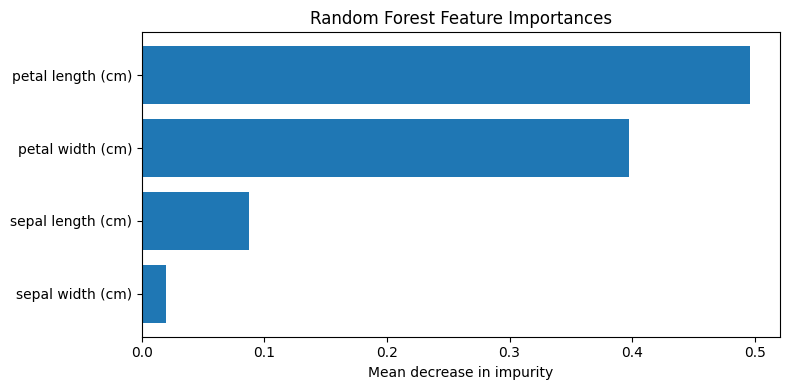

In [7]:
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_,
}).sort_values("Importance", ascending=False)

display(importance_df.round(4))

plt.figure(figsize=(8, 4))
plt.barh(
    importance_df["Feature"][::-1],
    importance_df["Importance"][::-1],
)
plt.xlabel("Mean decrease in impurity")
plt.title("Random Forest Feature Importances")
plt.tight_layout()
plt.show()

## 4. Gradient boosting machines

**Gradient boosting** builds a sequence of small decision trees. Each new tree is trained to improve on the current model by focusing on errors made by previous steps. The final prediction combines the contributions of the sequence.

This differs from random forests, whose trees are generally trained independently and then aggregated.

Key parameters include:

- `n_estimators`: number of boosting stages (trees).
- `learning_rate`: scales the contribution of each stage.
- `max_depth`: complexity of the individual trees.
- `subsample`: fraction of training samples used for each boosting stage.

A lower learning rate often needs more boosting stages. Excessive complexity or too many stages can still overfit, so validation is important.

In [8]:
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=2,
    random_state=RANDOM_STATE,
)
gb_model.fit(X_train, y_train)

gb_predictions = gb_model.predict(X_test)
gb_accuracy = accuracy_score(y_test, gb_predictions)

print(f"Gradient Boosting test accuracy: {gb_accuracy:.3f}")
print("\nClassification report:")
print(
    classification_report(
        y_test,
        gb_predictions,
        target_names=class_names,
        zero_division=0,
    )
)

Gradient Boosting test accuracy: 0.911

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.87      0.87      0.87        15
   virginica       0.87      0.87      0.87        15

    accuracy                           0.91        45
   macro avg       0.91      0.91      0.91        45
weighted avg       0.91      0.91      0.91        45



### Observing the effect of the learning rate

The following small experiment compares several learning-rate choices while keeping the number and depth of boosting stages fixed. It is a simple illustration, not a substitute for cross-validation or a full parameter search.

In [9]:
learning_rate_results = []

for learning_rate in [0.03, 0.1, 0.3]:
    candidate = GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=learning_rate,
        max_depth=2,
        random_state=RANDOM_STATE,
    )
    candidate.fit(X_train, y_train)
    learning_rate_results.append({
        "Learning rate": learning_rate,
        "Training accuracy": candidate.score(X_train, y_train),
        "Test accuracy": candidate.score(X_test, y_test),
    })

pd.DataFrame(learning_rate_results).round(3)

,Learning rate,Training accuracy,Test accuracy
0,0.03,1.0,0.933
1,0.10,1.0,0.911
2,0.30,1.0,0.911


## 5. Hyperparameter tuning for trees and ensembles

A **hyperparameter** is a setting chosen before model fitting, such as the maximum tree depth or number of estimators. `GridSearchCV` tests the combinations specified in a parameter grid using cross-validation on the training set.

The test set should remain separate until the final evaluation. Using test-set performance to choose hyperparameters would leak information from the final evaluation into the tuning process.

### Grid search for Gradient Boosting

We will compare a small set of values for `n_estimators`, `learning_rate`, and `max_depth`. The best combination is selected using mean cross-validation accuracy on the training data.

In [10]:
gb_param_grid = {
    "n_estimators": [50, 100],
    "learning_rate": [0.05, 0.1],
    "max_depth": [1, 2],
}

gb_search = GridSearchCV(
    estimator=GradientBoostingClassifier(random_state=RANDOM_STATE),
    param_grid=gb_param_grid,
    scoring="accuracy",
    cv=5,
    n_jobs=-1,
)
gb_search.fit(X_train, y_train)

print("Best parameters:", gb_search.best_params_)
print(f"Best mean CV accuracy: {gb_search.best_score_:.3f}")

tuned_gb_model = gb_search.best_estimator_
tuned_gb_predictions = tuned_gb_model.predict(X_test)
print(f"Tuned Gradient Boosting test accuracy: {accuracy_score(y_test, tuned_gb_predictions):.3f}")

Best parameters: {'learning_rate': 0.05, 'max_depth': 1, 'n_estimators': 100}
Best mean CV accuracy: 0.962
Tuned Gradient Boosting test accuracy: 0.933


### Inspecting cross-validation results

The search results show how different parameter combinations performed across the validation folds. They can help diagnose whether a parameter change gives a consistent improvement or only a small difference.

In [11]:
gb_cv_results = pd.DataFrame(gb_search.cv_results_)[
    [
        "param_n_estimators",
        "param_learning_rate",
        "param_max_depth",
        "mean_test_score",
        "std_test_score",
        "rank_test_score",
    ]
].sort_values("rank_test_score")

gb_cv_results.head(10).round(4)

,param_n_estimators,param_learning_rate,param_max_depth,mean_test_score,std_test_score,rank_test_score
1,100,0.05,1,0.9619,0.019,1
3,100,0.05,2,0.9619,0.019,1
5,100,0.10,1,0.9619,0.019,1
4,50,0.10,1,0.9619,0.019,1
2,50,0.05,2,0.9524,0.000,5
0,50,0.05,1,0.9524,0.000,5
6,50,0.10,2,0.9524,0.000,5
7,100,0.10,2,0.9524,0.000,5


## 6. Comparing ensemble methods

Different ensemble strategies combine models in different ways:

- **Bagging / Random Forest:** trains models independently on varied samples and aggregates their predictions; often helps reduce variance.
- **Boosting / Gradient Boosting:** adds models sequentially so later models improve the combined prediction.
- **Stacking:** trains a final model to combine predictions from different base estimators. Here, a logistic regression model serves as the final estimator.

There is no universally best method. The most suitable model depends on the dataset, performance metric, training cost, and interpretability needs.

### Train and compare Random Forest, Gradient Boosting, and Stacking

In [12]:
stack_model = StackingClassifier(
    estimators=[
        (
            "random_forest",
            RandomForestClassifier(
                n_estimators=100,
                random_state=RANDOM_STATE,
            ),
        ),
        (
            "gradient_boosting",
            GradientBoostingClassifier(
                n_estimators=100,
                learning_rate=0.1,
                max_depth=2,
                random_state=RANDOM_STATE,
            ),
        ),
    ],
    final_estimator=LogisticRegression(max_iter=2000),
    cv=5,
)

comparison_models = {
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE,
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=2,
        random_state=RANDOM_STATE,
    ),
    "Stacking": stack_model,
}

comparison_rows = []
fitted_models = {}

for model_name, model in comparison_models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    fitted_models[model_name] = model
    comparison_rows.append({
        "Model": model_name,
        "Training accuracy": accuracy_score(y_train, model.predict(X_train)),
        "Test accuracy": accuracy_score(y_test, predictions),
    })

comparison_df = pd.DataFrame(comparison_rows).sort_values(
    "Test accuracy", ascending=False
).reset_index(drop=True)

comparison_df.round(3)

,Model,Training accuracy,Test accuracy
0,Random Forest,1.0,0.933
1,Stacking,1.0,0.933
2,Decision Tree,1.0,0.911
3,Gradient Boosting,1.0,0.911


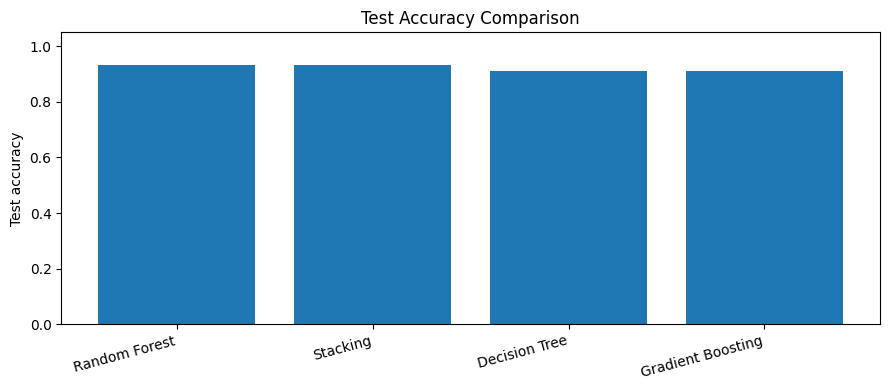

In [13]:
plt.figure(figsize=(9, 4))
plt.bar(
    comparison_df["Model"],
    comparison_df["Test accuracy"],
)
plt.ylim(0, 1.05)
plt.ylabel("Test accuracy")
plt.title("Test Accuracy Comparison")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

### Compare confusion matrices

Accuracy gives one overall score, but it does not show which classes are being confused. Confusion matrices provide a more detailed view of each model's test-set predictions.

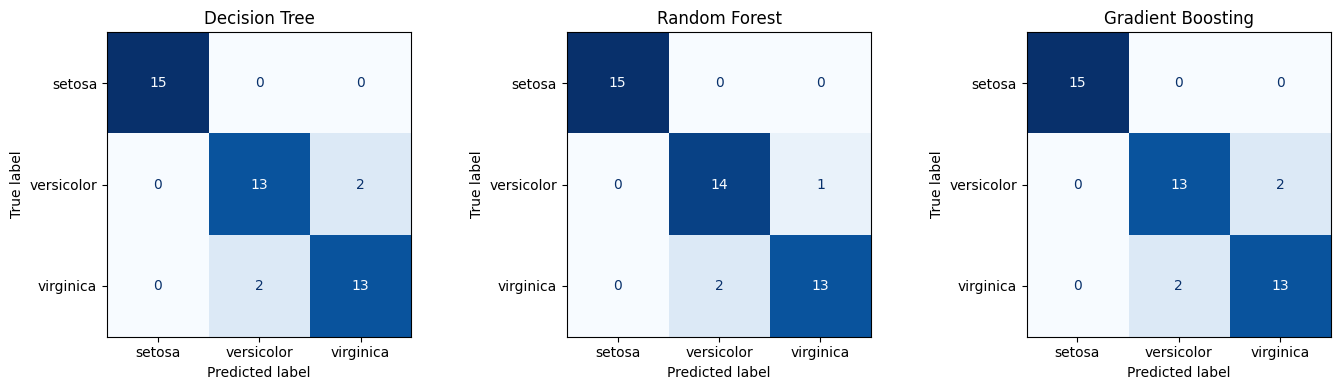

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
models_to_display = ["Decision Tree", "Random Forest", "Gradient Boosting"]

for ax, model_name in zip(axes, models_to_display):
    ConfusionMatrixDisplay.from_estimator(
        fitted_models[model_name],
        X_test,
        y_test,
        display_labels=class_names,
        cmap="Blues",
        ax=ax,
        colorbar=False,
    )
    ax.set_title(model_name)

plt.tight_layout()
plt.show()

## 7. Practical exercises

The following exercises reflect the practical goals of the chapter. Use the outputs to write your own interpretation; model scores may differ from examples in the book because the experiment setup or library version can differ.

### Exercise 1 — Build and evaluate a decision tree classifier

Train a decision tree, make predictions on the held-out test set, and inspect both accuracy and the confusion matrix.

Exercise 1 accuracy: 0.911
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.87      0.87      0.87        15
   virginica       0.87      0.87      0.87        15

    accuracy                           0.91        45
   macro avg       0.91      0.91      0.91        45
weighted avg       0.91      0.91      0.91        45



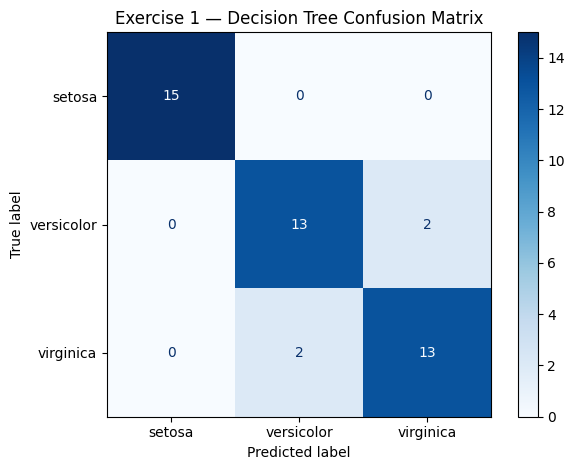

In [15]:
exercise_tree = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=4,
    random_state=RANDOM_STATE,
)
exercise_tree.fit(X_train, y_train)
exercise_tree_pred = exercise_tree.predict(X_test)

print(f"Exercise 1 accuracy: {accuracy_score(y_test, exercise_tree_pred):.3f}")
print(classification_report(
    y_test,
    exercise_tree_pred,
    target_names=class_names,
    zero_division=0,
))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    exercise_tree_pred,
    display_labels=class_names,
    cmap="Blues",
)
plt.title("Exercise 1 — Decision Tree Confusion Matrix")
plt.tight_layout()
plt.show()

### Exercise 2 — Tune a random forest with grid search

Search over a compact grid of forest sizes and tree-depth limits. Use the best model selected by cross-validation to evaluate the untouched test set.

In [16]:
rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 3, 5],
    "min_samples_leaf": [1, 2],
}

rf_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE),
    param_grid=rf_param_grid,
    scoring="accuracy",
    cv=5,
    n_jobs=-1,
)
rf_search.fit(X_train, y_train)

best_rf_model = rf_search.best_estimator_
best_rf_pred = best_rf_model.predict(X_test)

print("Best Random Forest parameters:", rf_search.best_params_)
print(f"Best mean CV accuracy: {rf_search.best_score_:.3f}")
print(f"Test accuracy: {accuracy_score(y_test, best_rf_pred):.3f}")

Best Random Forest parameters: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}
Best mean CV accuracy: 0.962
Test accuracy: 0.933


### Exercise 3 — Compare Gradient Boosting and Random Forest

Compare the two ensemble families on the same training and test split. Which has the higher test accuracy in this run? Do not assume that the higher score is always better in every dataset.

In [17]:
exercise_comparison = pd.DataFrame([
    {
        "Model": "Random Forest",
        "Test accuracy": accuracy_score(y_test, best_rf_model.predict(X_test)),
    },
    {
        "Model": "Gradient Boosting",
        "Test accuracy": accuracy_score(y_test, tuned_gb_model.predict(X_test)),
    },
]).sort_values("Test accuracy", ascending=False)

exercise_comparison.round(3)

,Model,Test accuracy
0,Random Forest,0.933
1,Gradient Boosting,0.933


## 8. Reflection questions

Answer these questions in your own words after running the notebook:

1. Why can an unrestricted decision tree overfit?
2. How does random forest differ from a single decision tree?
3. What is the main difference between bagging and boosting?
4. What does `learning_rate` control in Gradient Boosting?
5. Why should hyperparameter tuning use cross-validation on the training set rather than the test set?
6. In what situations might stacking be useful?
7. Why should feature importance not automatically be interpreted as causal evidence?

## Chapter summary

- **Decision trees** create interpretable feature-based rules but can overfit when too complex.
- **Random forests** aggregate many randomized trees through bagging, commonly reducing the variance of a single tree.
- **Gradient boosting** builds trees sequentially to improve the combined model.
- **Hyperparameter tuning** with grid search and cross-validation helps choose settings without using the test set for model selection.
- **Stacking** combines different base estimators through a final estimator.
- **Model comparison** should consider more than one metric and should be based on a consistent data split.

The best choice is data-dependent. Compare models on held-out data and select metrics that match the real problem.